In [45]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [46]:
import pandas as pd
import numpy as np
df = pd.read_csv("L8_sales_data.csv")
df.shape

(1030, 14)

In [47]:
dates = ["order_date", "shipping_date",
"delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

In [48]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [49]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [50]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
count = (df["date_error"] == True).sum()
df.to_csv("sales_clean.csv", index=False)
print(f'{count}건, ', end="")
print(df.shape)


147건, (1004, 15)


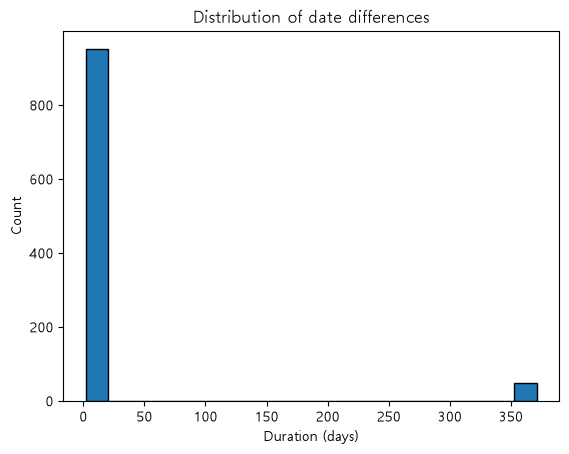

21.127127127127128 4.0


In [51]:
#5. 배송기간(도착일 - 배송일)은 보통 며칠인가
days = (df["delivery_date"] - df["order_date"]).dt.days.dropna().to_numpy()

plt.hist(days, bins=20, edgecolor='black')
plt.xlabel('Duration (days)')
plt.ylabel('Count')
plt.title('Distribution of date differences')
plt.show()

print(np.mean(days), end=" ")
print(np.median(days))

평균: 21.127, 중앙값: 4
이 둘이 크게 다른 이유는 히스토그램을 보았을 때 일부 데이터의 값이 너무 크기 때문에 평균은 높아지지만 중앙값은 데이터 내 값들 중에서 중앙에 위치한 값을 나타내기 때문이다.
따라서 이상치라고 판단되는 오른쪽 덩어리 데이터는 삭제하는 것이 전체 데이터의 학습에 도움이 된다.

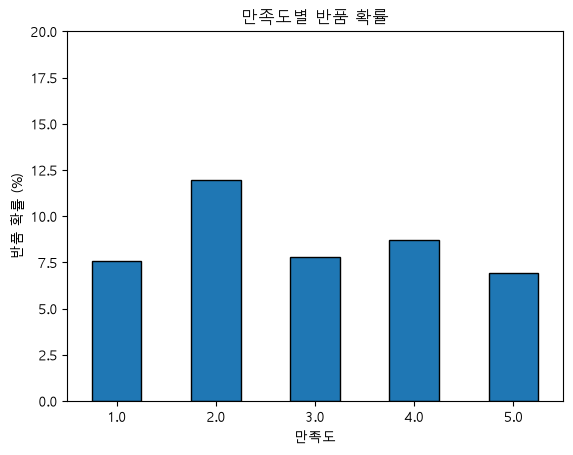

In [52]:
#6. 만족도가 낮을수록 반품이 많은가
return_rate = (
    (df["status"] == "반품")
    .groupby(df["satisfaction"])
    .mean() * 100
)

return_rate.plot(kind='bar', edgecolor='black', rot=0)

plt.xlabel('만족도')
plt.ylabel('반품 확률 (%)')
plt.title('만족도별 반품 확률')
plt.ylim(0, 20)
plt.show()

만족도 별 반품률
1.0     7.589286
2.0    11.956522
3.0     7.812500
4.0     8.720930
5.0     6.930693
답: 그렇다

In [55]:
#7. 카테고리 매출 1위의 이유는  건수 · 단가 · 수량 중 무엇인가
summary = (
    df.groupby('category', as_index=False)
    .agg(
        건수=('total_sales', 'size'),
        총매출=('total_sales', 'sum'),
        평균단가=('unit_price', 'mean'),
        평균수량=('quantity', 'mean')
    )
    .sort_values('총매출', ascending=False)
    .reset_index(drop=True)
)

display(summary.round(2))

,category,건수,총매출,평균단가,평균수량
0,가구,213,2.843337e+09,257322.91,51.04
1,식품,210,2.513274e+09,255232.93,47.31
2,전자제품,207,2.471628e+09,249651.61,47.96
3,도서,204,2.453240e+09,238500.64,49.50
4,의류,170,2.181904e+09,249447.16,51.61


가구는 2위인 식품과 비교해서 건수가 높고 평균 단가도 높고 평균 수량도 높지만 가장 두드러진 차이는 평균 수량으로 가구의 51.04애 비해 식품은 47.31에 그친다.
따라서 수량이 주된 요인이다.